# Vocabulary shift in ISMIR papers after ChatGPT

The compact version of `word_frequency.ipynb`: only the tests the conclusion needs, their assumptions, and the
figure for the paper.

| Question | Test |
|---|---|
| 1. Which words changed? | Fisher's exact test per word, Benjamini–Hochberg, bootstrap CIs |
| 2. Is it more than normal drift? | Same-gap year pairs; excess over the 2020–2022 trend, with a placebo |
| 3. Is it the topic? | Test 1 again without the papers about LLMs |
| 4. Do the assumptions hold? | Independence (labs), dependence between words |

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from matplotlib.transforms import blended_transform_factory
from scipy.stats import false_discovery_control, fisher_exact, norm

JSONL = Path("../data/processed/ismir_2020_2025_v2.jsonl")
CACHE = Path("../data/interim/lemmas_v2.json")  # spaCy output, shared with word_frequency.ipynb
FIGURES = Path("figures")
PERIODS = {2020: "before", 2021: "before", 2022: "before", 2023: "transition", 2024: "after", 2025: "after"}
POS = ("ADJ", "ADV", "VERB")  # style words; nouns (mostly topic) and proper nouns are left out
MIN_CHARS = 3
EXCLUDED = {"acknowledgments", "ethics", "appendix"}  # not style text, see the README
N_WORDS = 1500
FDR = 0.05
N_BOOT = 2000
N_REPEAT = 20  # repetitions of the random robustness check
SEED = 0

# Figure style: Nature-like (sans-serif 5-7 pt, thin axes, no grid, panel letters), sized for the paper.
MM = 1 / 25.4
WIDTH = 120 * MM  # LNCS text width is 122 mm (Nature: 89 mm one column, 183 mm two columns)
INK, MUTED, LIGHT, RED = "#1f1f1f", "#7a7974", "#c9c8c2", "#e34948"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6,
    "axes.titlesize": 7, "axes.titleweight": "normal", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": INK,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "xtick.direction": "out", "ytick.direction": "out",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "lines.linewidth": 1,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "figure.dpi": 200,
})
FIGURES.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def panel(ax, letter, dx=-0.2, dy=1.02):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left")


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIGURES / f"{name}.{ext}", bbox_inches="tight", dpi=600)

## 1. Feature and procedure

- **Text.** The whole paper: abstract and all sections except acknowledgments, ethics statements and appendices.
  Ethics statements only became common in 2024, so including them would bias the comparison.
- **Words.** Each text is lemmatized with spaCy (*delves, delved → delve*). We keep adjectives, adverbs and verbs of
  three or more letters and drop stop words and nouns, which mostly carry the topic.
- **Document frequency (DF)** of a word = the share of papers whose text contains it at least once. It does not depend
  on paper length, and one paper that repeats a word cannot dominate (as in Kobak et al., 2025).
- **Words tested:** the 1,500 lemmas with the highest DF.
- **Periods:** *before* = 2020–2022, *after* = 2024–2025. 2023 (submitted a few months after ChatGPT's release on
  30 Nov 2022) is a transition year: shown, not used in the main test.
- **Lab** of a paper = its last author (usually the senior author). Used only to check independence (Section 5).

In [2]:
def style_text(paper: dict) -> str:
    parts = [paper["abstract"]] + [s["text"] for s in paper["sections"] if not EXCLUDED & set(s["labels"])]
    return "\n\n".join(p for p in parts if p)


def keep(token) -> bool:
    return token.pos_ in POS and token.is_alpha and not token.is_stop and len(token) >= MIN_CHARS


papers = [json.loads(line) for line in JSONL.open()]
settings = {"jsonl": JSONL.name, "pos": list(POS), "min_chars": MIN_CHARS, "excluded": sorted(EXCLUDED),
            "spacy": spacy.__version__}
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
if cache.get("settings") != settings:  # about 1 minute
    nlp = spacy.load("en_core_web_sm", exclude=["parser", "ner"])
    docs = nlp.pipe((style_text(p) for p in papers), batch_size=16, n_process=4)
    lemmas = {p["paper_id"]: sorted({t.lemma_.lower() for t in d if keep(t)}) for p, d in zip(papers, docs)}
    cache = {"settings": settings, "lemmas": lemmas}
    CACHE.write_text(json.dumps(cache))

meta = pd.DataFrame({"year": [p["year"] for p in papers],
                     "lab": [p["authors"].split(",")[-1].strip() for p in papers]},
                    index=[p["paper_id"] for p in papers])
meta["period"] = meta.year.map(PERIODS)
YEARS = sorted(meta.year.unique())
df_all = pd.Series([w for ws in cache["lemmas"].values() for w in ws]).value_counts()
words = sorted(df_all.index, key=lambda w: (-df_all[w], w))[:N_WORDS]
sets = {i: set(ws) for i, ws in cache["lemmas"].items()}
X = pd.DataFrame([[w in sets[i] for w in words] for i in meta.index], index=meta.index, columns=words)
before, after = meta.index[meta.period == "before"], meta.index[meta.period == "after"]
print(f"{len(meta)} papers; last tested word in {df_all[words[-1]] / len(meta):.0%} of papers")
meta.groupby("year").agg(papers=("period", "size"), period=("period", "first"))

655 papers; last tested word in 4% of papers


,papers,period
year,,
2020,115,before
2021,104,before
2022,113,before
2023,101,transition
2024,123,after
2025,99,after


## 2. Test 1 – Which words changed?

For each word, a 2×2 table (before/after × contains/doesn't) is tested with **Fisher's exact test** (two-sided), and
the 1,500 p-values are corrected with **Benjamini–Hochberg** (q < 0.05: at most 5% of the reported words are expected
to be false positives). Effect sizes: difference in DF (percentage points, pp) and ratio, with 95% percentile CIs
from 2,000 bootstrap resamples of papers (each period resampled separately).

*Assumptions:* papers are independent; within a period every paper has the same chance of using the word; for BH,
the 1,500 tests are independent or positively dependent. The first and the last do not fully hold (Section 5).

In [3]:
def bootstrap_df(m: np.ndarray) -> np.ndarray:
    """DF of each column of m in N_BOOT resamples of its rows (papers)."""
    n = len(m)
    draws = rng.multinomial(n, np.full(n, 1 / n), size=N_BOOT)
    return draws @ m.astype(float) / n


def fisher_q(a: np.ndarray, b: np.ndarray, method: str = "bh") -> tuple[np.ndarray, np.ndarray]:
    """Fisher's exact test per column of two boolean matrices; returns (p, q)."""
    na, nb, ka, kb = len(a), len(b), a.sum(0), b.sum(0)
    p = np.array([fisher_exact([[x, na - x], [y, nb - y]]).pvalue for x, y in zip(ka, kb)])
    return p, false_discovery_control(p, method=method)


def changed(a, b, method="bh") -> pd.Series:
    """'rose' / 'fell' / 'no change' per word, from group a to group b."""
    _, q = fisher_q(a.to_numpy(), b.to_numpy(), method)
    d = b.to_numpy().mean(0) - a.to_numpy().mean(0)
    return pd.Series(np.where(q >= FDR, "no change", np.where(d > 0, "rose", "fell")), index=a.columns)


def compare(a: pd.DataFrame, b: pd.DataFrame) -> pd.DataFrame:
    """Per word: DF in a and b, Fisher's test, BH q-value, bootstrap CIs of the difference and the ratio."""
    am, bm = a.to_numpy(), b.to_numpy()
    p, q = fisher_q(am, bm)
    da, db = am.mean(0), bm.mean(0)
    boot_a, boot_b = bootstrap_df(am), bootstrap_df(bm)
    diff_ci = np.percentile(100 * (boot_b - boot_a), [2.5, 97.5], axis=0)
    with np.errstate(divide="ignore", invalid="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # the ratio is inf when a word is absent in a
        ratio_ci = np.nanpercentile(boot_b / boot_a, [2.5, 97.5], axis=0)
        ratio = db / da
    res = pd.DataFrame({
        "before_%": 100 * da, "after_%": 100 * db,
        "diff_pp": 100 * (db - da), "diff_lo": diff_ci[0], "diff_hi": diff_ci[1],
        "ratio": ratio, "ratio_lo": ratio_ci[0], "ratio_hi": ratio_ci[1], "p": p, "q": q,
    }, index=a.columns)
    res["change"] = np.where(res.q >= FDR, "no change", np.where(res.diff_pp > 0, "rose", "fell"))
    return res.sort_values("diff_pp", ascending=False)


res = compare(X.loc[before], X.loc[after])
rose, fell = res.index[res.change == "rose"], res.index[res.change == "fell"]
print(f"{len(before)} papers before, {len(after)} after: {len(rose)} words rose, {len(fell)} fell, "
      f"{(res.change == 'no change').sum()} no change")


def show(table: pd.DataFrame) -> pd.DataFrame:
    out = table[["before_%", "after_%"]].round(0).astype(int)
    out["difference (pp)"] = [f"{d:+.0f} [{lo:+.0f}, {hi:+.0f}]" for d, lo, hi in table[["diff_pp", "diff_lo", "diff_hi"]].values]
    out["ratio"] = [f"{r:.1f} [{lo:.1f}, {hi:.1f}]" for r, lo, hi in table[["ratio", "ratio_lo", "ratio_hi"]].values]
    out["q"] = table.q.map("{:.0e}".format)
    return out


pd.concat([show(res.loc[rose].head(10)), show(res.loc[fell].tail(5))])

332 papers before, 222 after: 172 words rose, 45 fell, 1283 no change


,before_%,after_%,difference (pp),ratio,q
assess,32,67,"+34 [+26, +43]","2.1 [1.7, 2.5]",1e-12
additionally,36,69,"+33 [+25, +41]","1.9 [1.6, 2.3]",9e-12
enhance,22,54,"+32 [+25, +40]","2.5 [2.0, 3.2]",3e-12
offer,32,63,"+31 [+23, +39]","2.0 [1.7, 2.4]",6e-11
leverage,28,59,"+31 [+23, +39]","2.1 [1.7, 2.6]",6e-11
notably,14,44,"+30 [+22, +38]","3.1 [2.3, 4.3]",3e-12
effectively,22,50,"+28 [+20, +36]","2.3 [1.8, 2.9]",2e-09
highlight,32,58,"+26 [+18, +34]","1.8 [1.5, 2.2]",1e-07
fine,29,55,"+26 [+18, +34]","1.9 [1.5, 2.4]",1e-07
serve,32,58,"+26 [+18, +34]","1.8 [1.5, 2.2]",2e-07


## 3. Test 2 – Is it more than normal drift?

Word use changes every year. Two checks use 2020–2022, which no LLM could have influenced, as the baseline.

**(a) Same-gap year pairs.** Test 1 between single years two apart (about 100–120 papers each, so similar power).
If the vocabulary always drifted this much, pairs before ChatGPT would show as many changes as pairs across it.
Pairs that end in 2023 or earlier count as *without ChatGPT* (2023 papers were mostly written before its adoption).
*Assumptions:* as Test 1.

In [4]:
pairs = {(y0, y0 + gap): changed(X.loc[meta.year == y0], X.loc[meta.year == y0 + gap])
         for gap in (1, 2) for y0 in YEARS if y0 + gap in YEARS}
drift = pd.DataFrame([{"comparison": f"{y0} → {y1}", "gap": y1 - y0, "across ChatGPT": y1 >= 2024,
                       "rose": (r == "rose").sum(), "fell": (r == "fell").sum()}
                      for (y0, y1), r in pairs.items()]).set_index("comparison")
print(f"1-year gaps: at most {drift[drift.gap == 1][['rose', 'fell']].sum(axis=1).max()} changed words in any pair")
drift[drift.gap == 2]

1-year gaps: at most 4 changed words in any pair


,gap,across ChatGPT,rose,fell
comparison,,,,
2020 → 2022,2,False,0,0
2021 → 2023,2,False,0,0
2022 → 2024,2,True,20,3
2023 → 2025,2,True,45,6


**(b) Excess over the earlier trend** (after Kobak et al., 2025). Some words were already rising before 2022. For
each word, a straight line through its 2020–2022 yearly DFs is extended to 2024–2025. The slope may rise but is
never allowed to fall, so a word that was declining is expected to stay flat, which makes the test cautious.
*Excess* = observed − expected DF. It is tested one-sided with a z-score whose SD comes from the bootstrap (the trend
is refitted in every resample, so its uncertainty is included), then Benjamini–Hochberg. **Placebo:** the same
procedure with the 2020–2021 trend predicting 2022, where no excess should exist.

*Assumptions:* without ChatGPT, each word would have kept its linear (or flat) 2020–2022 trend. With only three
pre-ChatGPT years, this is the weakest assumption of the analysis: a trend that was accelerating anyway would appear
as excess. The placebo (two years predicting the third) finds none, but cannot rule out an acceleration that began
only in 2023–2024. The bootstrap distribution of the excess is assumed to be roughly normal (about 100 papers per
year). The number of words above the trend depends slightly on the bootstrap draw, because a few words sit near
q = 0.05; the cell after the next one measures this.

In [5]:
def year_df(y: int) -> np.ndarray:
    m = X.loc[meta.year == y].to_numpy(float)
    return np.vstack([m.mean(0), bootstrap_df(m)])  # row 0: observed; rows 1..: bootstrap


yearly_n = meta.groupby("year").size()


def trend_line(fit_years, df):
    """Least-squares line through yearly DFs, slope floored at 0. Returns (level, slope, centre year)."""
    t = np.array(fit_years, float)
    centre = t.mean()
    slope = ((t - centre)[:, None, None] * df).sum(0) / ((t - centre) ** 2).sum()
    return df.mean(0), np.maximum(slope, 0), centre


def excess_over_trend(boot, fit_years, target_years) -> pd.DataFrame:
    level, slope, centre = trend_line(fit_years, np.stack([boot[y] for y in fit_years]))
    weights = yearly_n.loc[target_years] / yearly_n.loc[target_years].sum()
    expected = sum(w * np.clip(level + slope * (y - centre), 0, 1) for y, w in weights.items())
    observed = sum(w * boot[y] for y, w in weights.items())
    excess = observed - expected
    with np.errstate(divide="ignore", invalid="ignore"):
        z = excess[0] / excess[1:].std(0)
    out = pd.DataFrame({"expected_%": 100 * expected[0], "observed_%": 100 * observed[0], "excess_pp": 100 * excess[0],
                        "z": z, "p": norm.sf(np.nan_to_num(z))}, index=words)
    out["q"] = false_discovery_control(out.p)
    return out.sort_values("excess_pp", ascending=False)


CHECKS = {
    "2020–22 trend → 2024–25 (test)": ([2020, 2021, 2022], [2024, 2025]),
    "2020–21 trend → 2022 (placebo)": ([2020, 2021], [2022]),
    "2020–22 trend → 2023 (transition)": ([2020, 2021, 2022], [2023]),
}
BOOT = {y: year_df(y) for y in YEARS}
excess = {name: excess_over_trend(BOOT, *yrs) for name, yrs in CHECKS.items()}
main = excess["2020–22 trend → 2024–25 (test)"]
above = main.index[main.q < FDR]
print(f"Above the trend in 2024–25: {len(above)} words, of which {len(above.intersection(rose))} also rose in Test 1:")
print(", ".join(main.loc[above].sort_values("z", ascending=False).index))
pd.DataFrame({name: {"words with p < 0.05": f"{(r.p < 0.05).mean():.1%}", "words above trend (q < 0.05)": (r.q < FDR).sum()}
              for name, r in excess.items()}).T

Above the trend in 2024–25: 42 words, of which 42 also rose in Test 1:
offer, additionally, enable, prompt, underscore, primarily, address, key, adhere, closely, serve, employ, notably, assess, showcase, overlook, suggest, arise, specifically, utilize, typically, encompass, emphasize, critical, incorporate, pose, capture, predominantly, prior, creative, inherent, subsequently, tuned, guide, acknowledge, accurately, progressively, source, support, undergo, broad, rely


,words with p < 0.05,words above trend (q < 0.05)
2020–22 trend → 2024–25 (test),8.9%,42
2020–21 trend → 2022 (placebo),1.5%,0
2020–22 trend → 2023 (transition),3.1%,0


In [6]:
seed_counts = []
for s in range(8):  # how much the count depends on the bootstrap draw
    rng_s = np.random.default_rng(1000 + s)
    boot_s = {}
    for y in YEARS:
        m = X.loc[meta.year == y].to_numpy(float)
        d = rng_s.multinomial(len(m), np.full(len(m), 1 / len(m)), size=N_BOOT)
        boot_s[y] = np.vstack([m.mean(0), d @ m / len(m)])
    seed_counts.append((excess_over_trend(boot_s, *CHECKS["2020–22 trend → 2024–25 (test)"]).q < FDR).sum())
print(f"Words above the trend across 8 other bootstrap seeds: {min(seed_counts)}–{max(seed_counts)} "
      f"(this run: {len(above)})")

Words above the trend across 8 other bootstrap seeds: 41–46 (this run: 42)


## 4. Test 3 – Is it the topic?

ISMIR's topics changed too: many 2024–2025 papers are about LLMs and might need words such as *prompt*. We run Test 1
again with only the after-papers that never mention LLMs, GPT or ChatGPT. If the shift came from the new topic, most
risers would disappear.

*Assumption:* the regular expression finds the papers about LLMs. It also flags papers that only cite an LLM, so it
removes more papers than needed, which makes the check cautious. It cannot remove other new topics; a few risers are
topic words (*prompt, fine, tuned, creative*).

In [7]:
LLM_TOPIC = re.compile(r"\b(?:large language models?|llms?|chatgpt|gpt(?:-?\d\w*)?)\b", re.I)
meta["about_llm"] = [bool(LLM_TOPIC.search(style_text(p))) for p in papers]
print(meta[meta.period != "transition"].groupby("period").about_llm.mean().map("{:.0%} mention LLMs".format).to_string())
not_llm = meta.index[(meta.period == "after") & ~meta.about_llm]
res_topic = compare(X.loc[before], X.loc[not_llm])
still = (res_topic.loc[rose, "change"] == "rose").sum()
r_topic = np.corrcoef(res.loc[words, "diff_pp"], res_topic.loc[words, "diff_pp"])[0, 1]
print(f"{len(not_llm)} after-papers without LLMs: {still} of the {len(rose)} risers still rise significantly; "
      f"correlation of the per-word changes with all after-papers r = {r_topic:.2f}")

period
after     25% mention LLMs
before     4% mention LLMs


167 after-papers without LLMs: 111 of the 172 risers still rise significantly; correlation of the per-word changes with all after-papers r = 0.96


## 5. Do the assumptions hold?

| Test | Assumption | Holds? | Check below |
|---|---|---|---|
| Fisher, bootstrap, year pairs | Papers are independent | **Not fully.** Papers from the same lab share a writing style | (a) one paper per lab; (b) lab-level bootstrap |
| Fisher | Within a period, every paper has the same chance of using a word | **Approximately.** Topics differ between papers | Test 3 |
| Fisher | Totals of the 2×2 table are fixed | Yes, by design. Choosing words by their total DF does not bias the test | – |
| Benjamini–Hochberg | Tests are independent or positively dependent | **Not guaranteed.** Words co-occur | (c) Benjamini–Yekutieli, valid under any dependence |
| Bootstrap CIs | Percentile intervals are accurate | Yes for common words; less so for words near 0% | – |
| Excess over trend | Linear (or flat) trend would have continued | **Strongest assumption** (3 years) | Placebo in Test 2b |
| All | Parsing and lemmatization errors are the same in every year | Assumed: the same pipeline and versions for all papers | – |

**(a) One paper per lab.** If labs inflate the counts, keeping one random paper per lab and period should lose more
risers than a random subsample of the same size (which loses power but keeps the labs).

In [8]:
labs = meta.lab.value_counts()
print(f"{labs.size} labs; {(labs > 1).sum()} with more than one paper, holding {labs[labs > 1].sum()} of "
      f"{len(meta)} papers ({labs[labs > 1].sum() / len(meta):.0%}); largest: {labs.iloc[0]} papers")

one_per_lab, random_same_size = [], []
for s in range(N_REPEAT):
    kept = meta.sample(frac=1, random_state=s).groupby(["lab", "period"]).head(1).index
    b, a = before.intersection(kept), after.intersection(kept)
    one_per_lab.append(changed(X.loc[b], X.loc[a]).value_counts())
    r = np.random.default_rng(s)
    random_same_size.append(changed(X.loc[r.choice(before, len(b), replace=False)],
                                    X.loc[r.choice(after, len(a), replace=False)]).value_counts())
indep = pd.DataFrame({
    "papers (before / after)": [f"{len(before)} / {len(after)}", f"{len(b)} / {len(a)}", f"{len(b)} / {len(a)}"],
    "rose": [len(rose), np.median([c.get("rose", 0) for c in one_per_lab]), np.median([c.get("rose", 0) for c in random_same_size])],
    "fell": [len(fell), np.median([c.get("fell", 0) for c in one_per_lab]), np.median([c.get("fell", 0) for c in random_same_size])],
}, index=["all papers", "one paper per lab (median of 20)", "random subsample, same size (median of 20)"])
indep

331 labs; 92 with more than one paper, holding 416 of 655 papers (64%); largest: 21 papers


,papers (before / after),rose,fell
all papers,332 / 222,172.0,45.0
one paper per lab (median of 20),201 / 138,85.5,13.0
"random subsample, same size (median of 20)",201 / 138,101.5,18.0


**(b) Lab-level bootstrap.** Resample whole labs instead of papers, so that a lab's papers stay together. If labs
mattered, the CIs would widen.

**(c) Benjamini–Yekutieli** replaces BH with a correction that is valid under any dependence between the tests (and is
much stricter).

In [9]:
def lab_boot_diff(values: pd.Series) -> np.ndarray:
    """Bootstrap of mean(after) - mean(before), resampling labs within each period."""
    out = []
    for idx in (before, after):
        groups = list(meta.loc[idx].groupby("lab").groups.values())
        sums = np.array([values[g].sum() for g in groups])
        sizes = np.array([len(g) for g in groups])
        draws = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=N_BOOT)
        out.append(draws @ sums / (draws @ sizes))
    return out[1] - out[0]


ci_rows = {}
for w in res.loc[rose].head(6).index:
    lab_ci = 100 * np.percentile(lab_boot_diff(X[w].astype(float)), [2.5, 97.5])
    ci_rows[w] = {"paper bootstrap": f"[{res.loc[w, 'diff_lo']:+.0f}, {res.loc[w, 'diff_hi']:+.0f}]",
                  "lab bootstrap": f"[{lab_ci[0]:+.0f}, {lab_ci[1]:+.0f}]"}
display(pd.DataFrame(ci_rows).T)

by = changed(X.loc[before], X.loc[after], method="by").value_counts()
print(f"(c) Benjamini–Yekutieli: {by.get('rose', 0)} rose, {by.get('fell', 0)} fell (BH: {len(rose)}, {len(fell)})")

,paper bootstrap,lab bootstrap
assess,"[+26, +43]","[+26, +43]"
additionally,"[+25, +41]","[+25, +41]"
enhance,"[+25, +40]","[+24, +40]"
offer,"[+23, +39]","[+23, +39]"
leverage,"[+23, +39]","[+23, +40]"
notably,"[+22, +38]","[+22, +37]"


(c) Benjamini–Yekutieli: 107 rose, 12 fell (BH: 172, 45)


**Summary.** Independence does not fully hold: most papers share their lab with another paper. Keeping one paper per
lab loses somewhat more risers than a random subsample of the same size, so the lab structure inflates the count of
significant words a little, but most of the drop is the smaller sample. The lab-level CIs are almost identical to the
paper-level ones, so the effect sizes are not affected. Benjamini–Yekutieli, which needs no assumption about the
dependence between words, still finds about 100 risers. The remaining weak point is the linear trend in Test 2b,
which rests on three years.

## 6. Evidence table

In [10]:
two = drift[drift.gap == 2]
fmt = lambda r: f"{r.rose + r.fell} ({r.name})"
evidence = pd.DataFrame([
    {"check": "Words that changed over a 2-year gap (Fisher, q < 0.05)",
     "without ChatGPT": ", ".join(fmt(r) for _, r in two[~two["across ChatGPT"]].iterrows()),
     "across ChatGPT": ", ".join(fmt(r) for _, r in two[two["across ChatGPT"]].iterrows())},
    {"check": "Words above the earlier trend (q < 0.05)",
     "without ChatGPT": f"{(excess['2020–21 trend → 2022 (placebo)'].q < FDR).sum()} (2020–21 trend → 2022)",
     "across ChatGPT": f"{len(above)} (2020–22 trend → 2024–25); {(excess['2020–22 trend → 2023 (transition)'].q < FDR).sum()} in 2023"},
    {"check": "Risers that still rise without papers about LLMs",
     "without ChatGPT": "–", "across ChatGPT": f"{still} of {len(rose)} (r = {r_topic:.2f})"},
]).set_index("check")
with pd.option_context("display.max_colwidth", 90):
    display(evidence)

,without ChatGPT,across ChatGPT
check,,
"Words that changed over a 2-year gap (Fisher, q < 0.05)","0 (2020 → 2022), 0 (2021 → 2023)","23 (2022 → 2024), 51 (2023 → 2025)"
Words above the earlier trend (q < 0.05),0 (2020–21 trend → 2022),42 (2020–22 trend → 2024–25); 0 in 2023
Risers that still rise without papers about LLMs,–,111 of 172 (r = 0.96)


## 7. Figure for the paper

**Figure 1.** (a) Change in document frequency from 2020–2022 to 2024–2025 for the 12 words that rose most and the
8 that fell most (all q < 0.05; red: rose, blue: fell), with 95% bootstrap CIs; the coloured numbers give the DF before → after.
(b) Yearly document frequency (share of papers using the word, 95% bootstrap CI) of the four words with the largest excess over their 2020–2022 trend
(dashed line, extended; slope not allowed to fall). Grey: 2020–2022, light grey: 2023, red: 2024–2025.

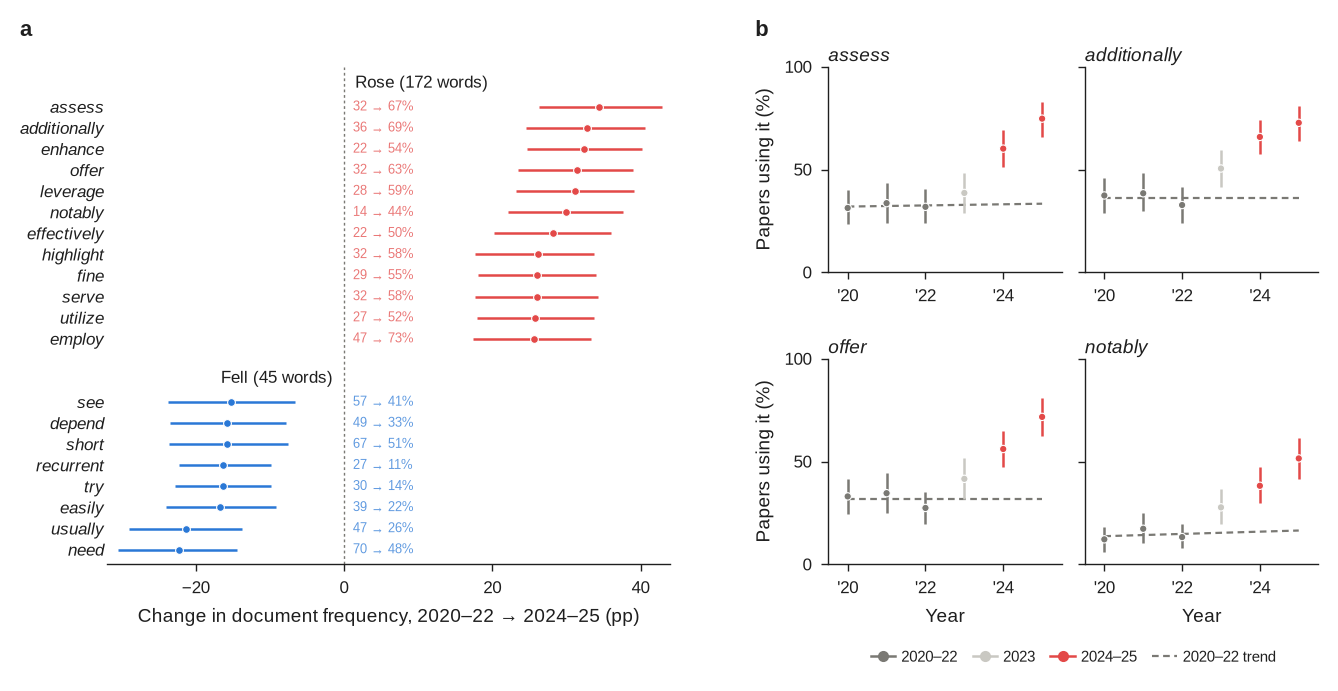

In [11]:
from matplotlib.lines import Line2D

t = np.array(YEARS)
year_labels = [f"'{y % 100}" for y in YEARS]
BLUE = "#2a78d6"  # fell (red = rose / after)


def letters(fig, groups):
    """Put bold panel letters at the top-left corner of each group of axes (labels included), on one baseline."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    inv = fig.transFigure.inverted()
    boxes = {k: [ax.get_tightbbox(renderer) for ax in axes] for k, axes in groups.items()}
    top = max(b.y1 for bs in boxes.values() for b in bs)
    for k, bs in boxes.items():
        x, y = inv.transform((min(b.x0 for b in bs), top))
        fig.text(x, y + 0.01, k, fontsize=8, fontweight="bold", ha="left", va="bottom")


fig = plt.figure(figsize=(170 * MM, 80 * MM))
outer = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], left=0.09, right=0.995, bottom=0.15, top=0.94, wspace=0.3)
ax_a = fig.add_subplot(outer[0])
inner = outer[1].subgridspec(2, 2, wspace=0.1, hspace=0.42)

# a: forest plot, risers above fallers; DF before -> after written on top of each bar
top_rose, top_fell = res.loc[rose].head(12), res.loc[fell].tail(8)
y_fell = np.arange(len(top_fell))[::-1].astype(float)
y_rose = np.arange(len(top_rose))[::-1] + len(top_fell) + 2.0
for tab, yy, color, header, hx, ha in [(top_rose, y_rose, RED, f"Rose ({len(rose)} words)", 1.5, "left"),
                                       (top_fell, y_fell, BLUE, f"Fell ({len(fell)} words)", -1.5, "right")]:
    ax_a.hlines(yy, tab.diff_lo, tab.diff_hi, color=color, linewidth=0.9)
    ax_a.plot(tab.diff_pp, yy, "o", color=color, markersize=2.8, markeredgecolor="white", markeredgewidth=0.4)
    for yv, (_, r) in zip(yy, tab.iterrows()):  # DF before -> after, in one column right of the zero line
        ax_a.text(1.2, yv, f"{r['before_%']:.0f} → {r['after_%']:.0f}%", ha="left", va="center",
                  fontsize=4.5, color=color, alpha=0.75)
    ax_a.text(hx, yy.max() + 1.1, header, ha=ha, va="center", fontsize=6, color=INK)
ax_a.axvline(0, color=MUTED, linewidth=0.5, linestyle=(0, (2, 2)))
ax_a.set_yticks(np.r_[y_rose, y_fell], list(top_rose.index) + list(top_fell.index), fontstyle="italic")
ax_a.tick_params(axis="y", length=0, pad=1)
ax_a.spines["left"].set_visible(False)
ax_a.set_xlim(-32, 44)
ax_a.set_xticks([-20, 0, 20, 40])
ax_a.set_ylim(-0.7, y_rose.max() + 1.9)
ax_a.set_xlabel("Change in document frequency, 2020–22 → 2024–25 (pp)")

# b: yearly DF and the 2020-22 trend for the strongest excess words
colors = np.where(t <= 2022, MUTED, np.where(t == 2023, LIGHT, RED))
examples = main.loc[above].sort_values("excess_pp", ascending=False).index[:4]
axes_b = [fig.add_subplot(inner[r, c]) for r in (0, 1) for c in (0, 1)]
for k, (ax, w) in enumerate(zip(axes_b, examples)):
    j = words.index(w)
    obs = np.array([100 * BOOT[y][0, j] for y in YEARS])
    lo, hi = (np.array([100 * np.percentile(BOOT[y][1:, j], q) for y in YEARS]) for q in (2.5, 97.5))
    level, slope, centre = trend_line([2020, 2021, 2022], np.stack([BOOT[y][:1, j:j + 1] for y in (2020, 2021, 2022)]))
    ax.plot(t, 100 * np.clip(level[0, 0] + slope[0, 0] * (t - centre), 0, 1), color=MUTED, linewidth=0.8,
            linestyle=(0, (3, 2)))
    ax.vlines(t, lo, hi, color=colors, linewidth=0.9)
    ax.scatter(t, obs, color=colors, s=7, zorder=3, edgecolor="white", linewidth=0.4)
    ax.set_title(w, fontstyle="italic", pad=2)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 50, 100])
    ax.set_xlim(2019.5, 2025.5)
    ax.set_xticks(YEARS[::2], year_labels[::2])
    if k % 2:
        ax.tick_params(axis="y", labelleft=False)
    else:
        ax.set_ylabel("Papers using it (%)")
    if k >= 2:
        ax.set_xlabel("Year")
handles = [Line2D([], [], color=MUTED, marker="o", markersize=3, linewidth=0.9, label="2020–22"),
           Line2D([], [], color=LIGHT, marker="o", markersize=3, linewidth=0.9, label="2023"),
           Line2D([], [], color=RED, marker="o", markersize=3, linewidth=0.9, label="2024–25"),
           Line2D([], [], color=MUTED, linewidth=0.8, linestyle=(0, (3, 2)), label="2020–22 trend")]
b_left, b_right = axes_b[2].get_position().x0, axes_b[3].get_position().x1
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=((b_left + b_right) / 2, 0.035), ncol=4,
           frameon=False, handlelength=1.6, columnspacing=1.0, handletextpad=0.4, fontsize=5.5)
letters(fig, {"a": [ax_a], "b": axes_b})
save(fig, "fig_vocab")
plt.show()